## Расчетно-графическая работа по математической статистике. Вариант A-2. Выполнил Григорьев Даниил, поток 21.1, P3216

Группа A, единицы измерения — мс, объем выборки $n = 200$.

### 1. Первичное описание выборки

In [2]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy import optimize
import math
from pathlib import Path
from IPython.display import display, Latex, Math
from sklearn.cluster import KMeans
from six import string_types
from statsmodels.distributions.empirical_distribution import ECDF

In [4]:
# 1. Загрузка данных
possible_paths = [
    Path('RGR1_A-2_X1-X4.csv'),
    Path('/mnt/data/RGR1_A-2_X1-X4.csv'),
]

for path in possible_paths:
    if path.exists():
        df = pd.read_csv(path)
        break
else:
    raise FileNotFoundError('Файл RGR1_A-2_X1-X4.csv не найден')

# 2. Объем выборки
n = len(df)
print(f"Объем выборки n = {n}")

# 3. Разделение на переменные
X1 = df['X1']
X2 = df['X2']
X3 = df['X3']
X4 = df['X4']

print(f'Минимум X1={np.min(X1)}')
print(f'Максимум X1={np.max(X1)}')
print()
print(f'Минимум X2={np.min(X2)}')
print(f'Максимум X2={np.max(X2)}')
print()
print(f'Минимум X3={np.min(X3)}')
print(f'Максимум X3={np.max(X3)}')
print()

Объем выборки n = 200
Минимум X1=28.81
Максимум X1=75.96

Минимум X2=26.8
Максимум X2=72.57

Минимум X3=22.47
Максимум X3=406.99



In [5]:
# 4. Вариационный ряд - просто сортировка

def variation(x):
    sorted_x = np.sort(x)
    return sorted_x[:10]  # Вывести первые 10 для примера


print(variation(X1))
print(variation(X2))
print(variation(X3))

[28.81 30.54 31.03 31.11 32.17 32.44 34.06 34.53 34.88 34.92]
[26.8  27.   27.53 27.57 27.62 28.39 28.61 28.71 29.35 29.58]
[22.47 22.76 22.89 22.98 23.53 23.8  24.05 24.47 25.21 25.68]


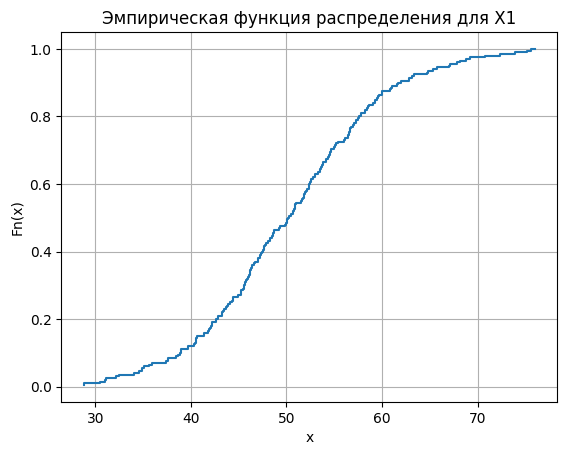

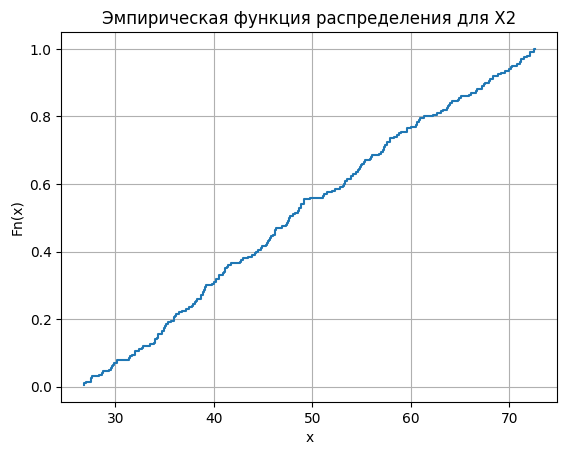

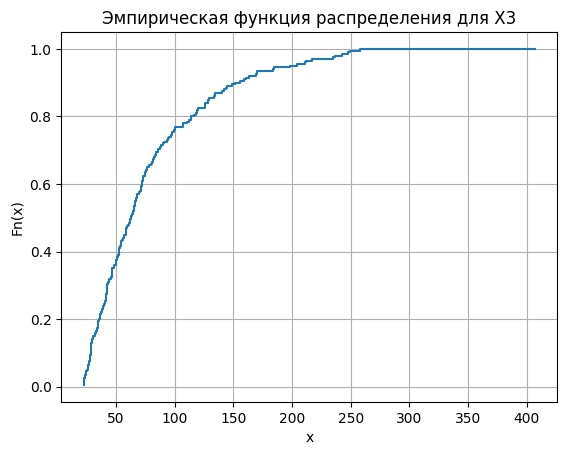

In [6]:
#5. Эмпирическая функция распределения

def empiric(x, place):
    ecdf_x = ECDF(x)
    plt.step(ecdf_x.x, ecdf_x.y)
    plt.title(f'Эмпирическая функция распределения для {place}')
    plt.xlabel('x')
    plt.ylabel('Fn(x)')
    plt.grid()
    plt.show()


empiric(X1, 'X1')
empiric(X2, 'X2')
empiric(X3, 'X3')

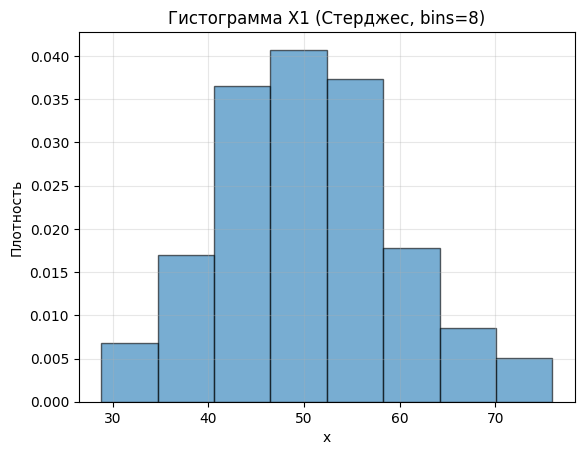

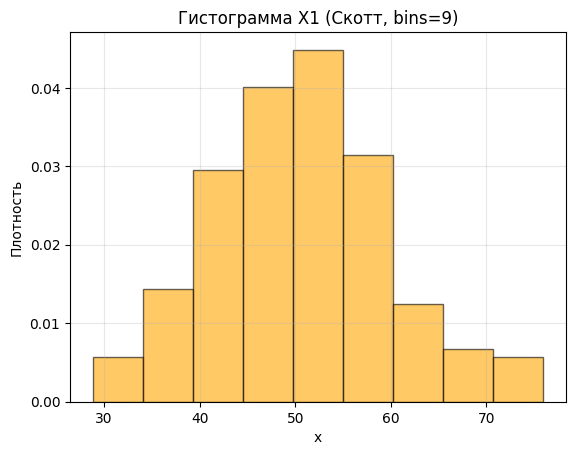

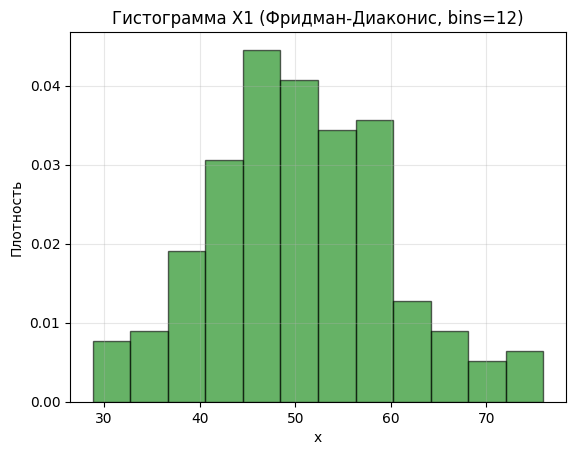

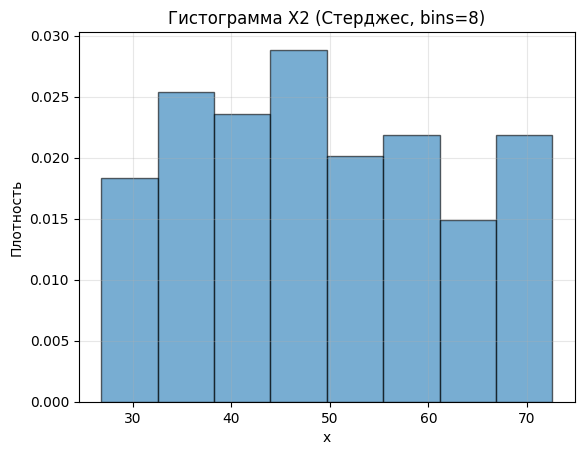

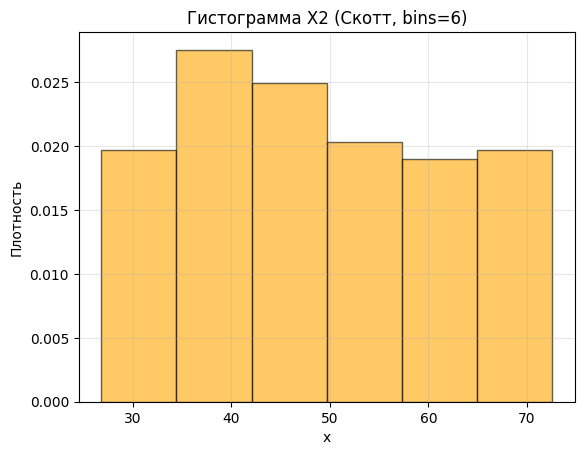

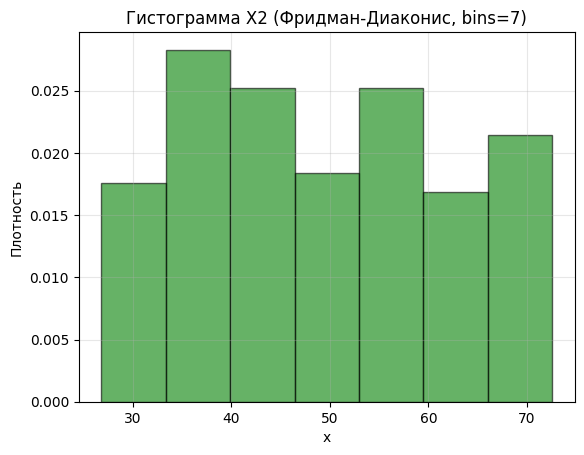

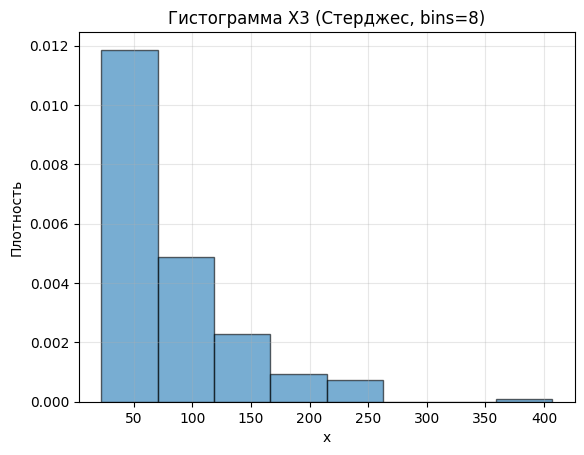

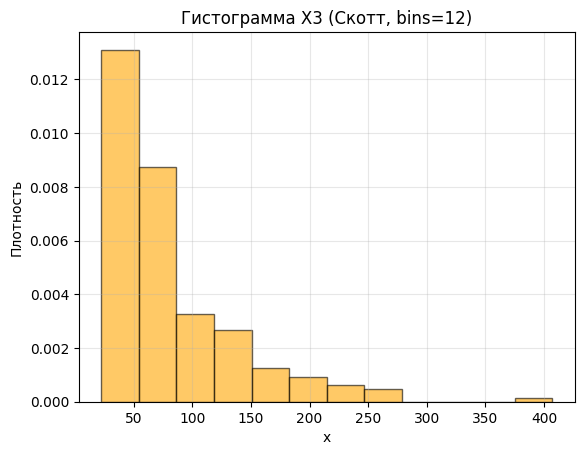

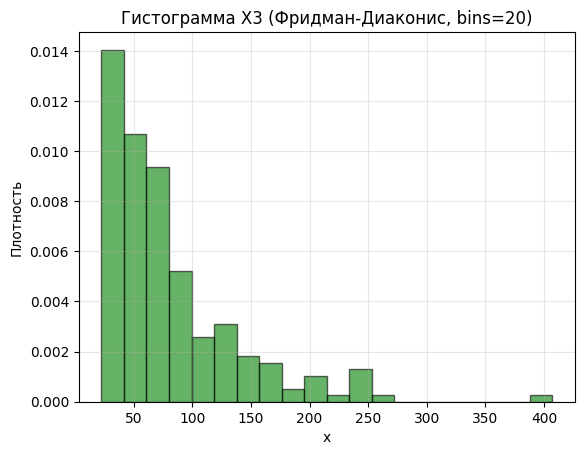

In [7]:
# 6. Гистограммы с разными правилами выбора интервалов

def sterges(x, place):
    n_bins_sturges = int(1 + np.log2(n))
    plt.hist(x, bins=n_bins_sturges, density=True, alpha=0.6, edgecolor='black')
    plt.title(f'Гистограмма {place} (Стерджес, bins={n_bins_sturges})')
    plt.xlabel('x')
    plt.ylabel('Плотность')
    plt.grid(True, alpha=0.3)
    plt.show()


def scott(x, place):
    h_scott = 3.5 * np.std(x, ddof=1) * n ** (-1 / 3)
    n_bins_scott = int(np.ceil((x.max() - x.min()) / h_scott))
    plt.hist(x, bins=n_bins_scott, density=True, alpha=0.6, edgecolor='black', color='orange')
    plt.title(f'Гистограмма {place} (Скотт, bins={n_bins_scott})')
    plt.xlabel('x')
    plt.ylabel('Плотность')
    plt.grid(True, alpha=0.3)
    plt.show()


def fridman_diaconis(x, place):
    iqr = np.percentile(x, 75) - np.percentile(x, 25)
    h_fd = 2 * iqr * n ** (-1 / 3)
    n_bins_fd = int(np.ceil((x.max() - x.min()) / h_fd))
    plt.hist(x, bins=n_bins_fd, density=True, alpha=0.6, edgecolor='black', color='green')
    plt.title(f'Гистограмма {place} (Фридман-Диаконис, bins={n_bins_fd})')
    plt.xlabel('x')
    plt.ylabel('Плотность')
    plt.grid(True, alpha=0.3)
    plt.show()


sterges(X1, 'X1')
scott(X1, 'X1')
fridman_diaconis(X1, 'X1')

sterges(X2, 'X2')
scott(X2, 'X2')
fridman_diaconis(X2, 'X2')

sterges(X3, 'X3')
scott(X3, 'X3')
fridman_diaconis(X3, 'X3')

In [8]:
def numerical_characteristics(x, place):
    x_bar = np.mean(x)
    S2 = np.var(x, ddof=0)  # по умолчанию смещенная
    sigma2_hat = np.var(x, ddof=1)  # указатель на несмещенную
    S = np.sqrt(S2)
    sigma_hat = np.sqrt(sigma2_hat)
    med = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)

    return f"{place}:\n среднее={x_bar:.2f}\n медиана={med:.2f}\n смещенная дисперсия={S2:.2f}\n несмещенная дисперсия={sigma2_hat:.2f}\n смещенное выборочное стандартное отклонение={S:.2f}\n несмещенное выборочное стандартное отклонение={sigma_hat:.2f}\n медиана={med:.2f}\n первый квартиль - 25-й процентиль={q1:.2f} - 25% данных меньше этого значения\n третий квартиль - 75-й процентиль={q3:.2f} - 75% данных меньше этого значения\n"


print(numerical_characteristics(X1, 'X1'))
print(numerical_characteristics(X2, 'X2'))
print(numerical_characteristics(X3, 'X3'))

X1:
 среднее=50.57
 медиана=50.34
 смещенная дисперсия=86.34
 несмещенная дисперсия=86.77
 смещенное выборочное стандартное отклонение=9.29
 несмещенное выборочное стандартное отклонение=9.32
 медиана=50.34
 первый квартиль - 25-й процентиль=44.39 - 25% данных меньше этого значения
 третий квартиль - 75-й процентиль=56.56 - 75% данных меньше этого значения

X2:
 среднее=49.10
 медиана=47.90
 смещенная дисперсия=166.74
 несмещенная дисперсия=167.58
 смещенное выборочное стандартное отклонение=12.91
 несмещенное выборочное стандартное отклонение=12.95
 медиана=47.90
 первый квартиль - 25-й процентиль=38.29 - 25% данных меньше этого значения
 третий квартиль - 75-й процентиль=59.17 - 75% данных меньше этого значения

X3:
 среднее=79.81
 медиана=63.35
 смещенная дисперсия=3301.58
 несмещенная дисперсия=3318.17
 смещенное выборочное стандартное отклонение=57.46
 несмещенное выборочное стандартное отклонение=57.60
 медиана=63.35
 первый квартиль - 25-й процентиль=41.16 - 25% данных меньше эт

#### Описание формы распределения

* X1:
    * Распределение близко к симметричному. Среднее значение (50.57) практически совпадает с медианой (50.34), разница составляет всего 0.23, что значительно меньше стандартного отклонения (9.32). Коэффициент асимметрии мал (0.27).
    * Сильных выбросов практически нет. Межквартильный размах IQR = 12.17. По правилу $Q_1 - 1.5 \cdot IQR;\ Q_3 + 1.5 \cdot IQR$ верхняя граница равна 74.81, поэтому только несколько верхних значений слегка выходят за нее; в целом основной массив наблюдений компактный.
    * Явные естественные границы отсутствуют. Значения варьируются от 28.81 до 75.96. Гистограмма не показывает жесткого обрыва ни слева, ни справа.
* X2:
    * Распределение близко к симметричному. Среднее значение (49.10) близко к медиане (47.90), разница составляет 1.20. Коэффициент асимметрии также мал (0.15).
    * Выбросы отсутствуют. Межквартильный размах IQR = 20.89. Все значения выборки (min=26.80, max=72.57) находятся в интервале $[6.96;\ 90.51]$.
    * Наблюдаются естественные нижняя и верхняя границы. По гистограмме видно, что данные заполняют конечный интервал примерно от 26.80 до 72.57 без длинных хвостов.
* X3:
    * Наблюдается выраженная правосторонняя асимметрия. Среднее значение (79.81) заметно превышает медиану (63.35), разница составляет 16.46, что указывает на длинный правый хвост распределения.
    * Выбросы присутствуют. Межквартильный размах IQR = 57.02. Верхняя граница по правилу $Q_3 + 1.5 \cdot IQR$ равна 183.72, однако максимальное значение выборки равно 406.99, что значительно превышает эту границу.
    * Имеется естественная нижняя граница. Минимальное значение выборки равно 22.47, все наблюдения лежат правее этой точки, при этом справа распределение имеет тяжелый хвост.

### 2. Предположение о виде закона распределения

X1:

Гистограмма X1 имеет колоколообразную и почти симметричную форму, что характерно для **нормального распределения**. Среднее (50.57) и медиана (50.34) практически совпадают, а эмпирическая функция распределения растет плавно без выраженных изломов. Небольшие отклонения в правом хвосте не меняют общей картины. Таким образом, наиболее подходящая модель - $N_{a,\sigma}$

X2:

Гистограмма X2 по форме близка к прямоугольной, а значения заполняют конечный интервал примерно равномерно, что характерно для **равномерного распределения**. Среднее (49.10) и медиана (47.90) близки, выраженной асимметрии нет. Эмпирическая функция распределения на основном промежутке близка к линейной. Таким образом, наиболее подходящая модель - $U_{a, b}$

X3:

Гистограмма X3 имеет убывающую форму с длинным правым хвостом, что характерно для **экспоненциального распределения со сдвигом**. Среднее (79.81) существенно больше медианы (63.35), что указывает на выраженную правостороннюю асимметрию. Все значения выборки лежат правее точки 22.47, что естественно интерпретировать как сдвиг. Таким образом, наиболее подходящая модель - $Exp_{\lambda,c}$

### 3. Оценивание параметров: метод моментов и метод максимального правдоподобия

#### X1: Нормальное распределение

1. Метод моментов

Для нормального распределения теоретические моменты имеют вид:

$EX = a, \ DX = \sigma^2$

Приравнивая теоретические моменты к выборочным характеристикам

$\hat{a}_{MM} = \bar{x} = 50.57$ - среднее арифметическое

$\hat{\sigma}_{MM} = S = \sqrt{S^2} = \sqrt{86.34} = 9.29$ - смещенное выборочное стандартное отклонение

2. Метод максимального правдоподобия

Функция правдоподобия: $L(a, \sigma) = \prod_{i = 1}^n \left(\frac{1}{\sigma\sqrt{2\pi}} \cdot \exp\left(-\frac{(x_i - a)^2}{2\sigma^2}\right)\right)$

Упростим: $L(a, \sigma) = \left(\frac{1}{\sigma\sqrt{2\pi}}\right)^n \cdot \exp\left(-\frac{\sum (x_i - a)^2}{2\sigma^2}\right)$

Логарифмическая функция правдоподобия: $l(a, \sigma) = \ln L(a, \sigma) = -n \ln(\sigma) - n \ln(\sqrt{2\pi}) - \frac{1}{2\sigma^2} \sum (x_i - a)^2$

**Находим оценку** для $a$ - берем частную производную по $a$ и приравниваем к 0

$\frac{\partial l}{\partial a} = \frac{1}{\sigma^2} \sum (x_i - a) = 0$

Значит $\sum (x_i - a) = 0 \Leftrightarrow a = \frac{\sum x_i}{n} = \bar{x}$

**Находим оценку** для $\sigma$ - берем частную производную по $\sigma$ и приравниваем к 0

$\frac{\partial l}{\partial \sigma} = -\frac{n}{\sigma} + \frac{1}{\sigma^3} \sum (x_i - a)^2 = 0$

Умножаем на $\sigma^3 \Rightarrow -n \sigma^2 + \sum (x_i - a)^2 = 0 \Rightarrow \sigma^2 = \frac{\sum (x_i - a)^2}{n} = S^2$

Таким образом, получаем, что $\sigma = \sqrt{S^2} = S$

Соответственно, для нормального распределения оба метода дают идентичные оценки. Это объясняется тем, что выборочное среднее и выборочная дисперсия являются достаточными статистиками для параметров нормального распределения.

#### X2: Равномерное распределение U(a, b)

Плотность распределения: $f(x) = \frac{1}{b - a}, \ a \leq x \leq b$

Теоретические моменты: $EX = \frac{a + b}{2}, \ DX = \frac{(b - a)^2}{12}$

1. Метод моментов

Приравниваем теоретические моменты к выборочным характеристикам

$\frac{a + b}{2} = \bar{x} = 49.10$

$\frac{(b - a)^2}{12} = S^2 = 166.74$

Из второго уравнения получаем $(b - a)^2 = 12 \cdot S^2 = 12 \cdot 166.74 = 2000.85 \Rightarrow b - a = \sqrt{12 \cdot S^2} = 44.73$

При этом из первого уравнения получаем, что $a + b = 2 \bar{x} = 2 \cdot 49.10 = 98.20$

Получается, решаем систему

$\left\{\begin{array}{c}
a + b = 98.20 \\
b - a = 44.73
\end{array}\right. \Rightarrow 2b = 142.93 \Rightarrow b = 71.465 \Rightarrow a = 26.734$

Таким образом, получаем, что $\hat{a}_{MM} = 26.734, \ \hat{b}_{MM} = 71.465$

2. Метод максимального правдоподобия

Функция правдоподобия $L(a, b) = \frac{1}{(b - a)^n}$ при условии $a \leq x_i \leq b$ для всех $i$

Для максимизации $L(a, b)$ необходимо минимизировать $(b - a)$. Это достигается при

* $a = \max$ возможное, но не превышающее $\min(x_i)$
* $b = \min$ возможное, но не меньшее $\max(x_i)$

Следовательно, $\hat{a}_{MMP} = \min(x_i) = 26.80, \ \hat{b}_{MMP} = \max(x_i) = 72.57$

Сравнение методов

| Параметр   | Метод моментов | ММП    | Различие |
|------------|----------------|--------|----------|
| a          | 26.734         | 26.80  | 0.066   |
| b          | 71.465         | 72.57  | 1.105   |

Оценки близки, но различаются. Метод моментов дает интервал $(26.734; 71.465)$, а ММП - $(26.80; 72.57)$. Различие объясняется тем, что ММП использует экстремальные статистики $\min$ и $\max$, которые естественно определяют границы равномерного распределения.

#### X3: Экспоненциальное распределение со сдвигом Exp(λ, c)

Плотность распределения - $f(x) = \lambda \cdot \exp\left(-\lambda(x - c)\right)$, $x \geq c, \ \lambda > 0$

Теоретические моменты:

* $EX = c + \frac{1}{\lambda}$
* $DX = \frac{1}{\lambda^2}$

1. Метод моментов

Приравниваем теоретические моменты к выборочным характеристикам

$c + \frac{1}{\lambda} = \bar{x} = 79.81$

$\frac{1}{\lambda^2} = S^2 = 3301.58$

Из второго уравнения получаем $\lambda = \frac{1}{\sqrt{S^2}} = \frac{1}{S} = \frac{1}{57.46} = 0.0174$

Из первого уравнения получаем $c = \bar{x} - \frac{1}{\lambda} = 79.81 - 57.46 = 22.35$

Таким образом получаем, что:

$\hat{c}_{MM} = 22.35, \ \hat{\lambda}_{MM} = 0.0174$

2. Метод максимального правдоподобия

$L(\lambda, c) = \lambda^n \cdot \exp\left(-\lambda \cdot \sum_{i = 1}^n (x_i - c)\right)$ при условии $x_i \geq c$

Логарифмическая функция правдоподобия

$l(\lambda, c) = n \cdot \ln(\lambda) - \lambda \cdot \sum_{i = 1}^n (x_i - c)$

Для максимизации $l(\lambda, c)$ необходимо выбрать $c$ как можно больше, но при этом есть условие, что $c \leq \min(x_i) \Rightarrow \hat{c}_{MMP} = \min(x_i) = 22.47$

При фиксированном $\hat{c}$ оценка $\lambda$ находится из условия $\frac{\partial l}{\partial \lambda} = \frac{n}{\lambda} - \sum(x_i - \hat{c}) = 0$

Тогда $\hat{\lambda}_{MMP} = \frac{n}{\sum (x_i - \hat{c})} = \frac{1}{\bar{x} - \hat{c}} = \frac{1}{79.81 - 22.47} = 0.0174$

Сравнение методов:

| Параметр   | Метод моментов | ММП    | Различие  |
|------------|----------------|--------|-----------|
| $c$        | 22.35         | 22.47   | 0.12     |
| $\lambda$ | 0.0174       | 0.0174 | 0.0000 |

Оценки практически совпадают. Метод моментов дает оценку сдвига $\hat{c} = 22.35$, а ММП оценивает сдвиг как минимальное значение выборки $\hat{c} = 22.47$. Такое малое расхождение означает, что выбранная экспоненциальная модель хорошо согласуется с данными.

### 4. Оценивание параметрической вероятности двумя способами

#### Формулы для каждого распределения

| Распределение                      | $P(X > x_0)$                                                                                                                                                        |
|------------------------------------|---------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Нормальное $N(a, \sigma)$          | $1 - \Phi\left(\frac{x_0 - a}{\sigma}\right)$, где $\Phi$ - функция стандартного нормального распределения                                                   |
| Равномерное $U(a, b)$              | $\left\{\begin{array}{c} \frac{b - x_0}{b - a}, \ \text{если} \ a \leq x_0 \leq b; \\ 1, \ \text{если} \ x_0 < a; \\ 0, \ \text{если} \ x_0 > b \end{array}\right.$ |
| Экспоненциальное $Exp(\lambda, c)$ | $\left\{\begin{array}{c} e^{-\lambda(x_0 - c)}, \ \text{если} \ x_0 \geq c; \\ 1, \ \text{если} \ x_0 < c \end{array}\right.$                                       |

#### Расчет для X1 - нормального распределения

Исходные данные:

* $\bar{x} = 50.57$
* $\hat{\sigma} = 9.32$ - несмещенное выборочное стандартное отклонение

**Выбираем порог**

$x_0 = \bar{x} + \hat{\sigma} = 50.57 + 9.32 = 59.88$

In [9]:
# Эмпирическая оценка

p_emp = sum(X1 > 59.88395) / n

print(p_emp)

0.14


Параметрическая оценка

$P(X > x_0) = 1 - \Phi\left(\frac{x_0 - a}{\sigma}\right) = 1 - \Phi\left(\frac{59.88 - 50.57}{9.29}\right) = 1 - \Phi\left(1.003\right) \approx 0.1580$

In [10]:
# Вычисление функции распределения стандартного нормального закона
import scipy.stats as stats

print(stats.norm.cdf(1))

0.8413447460685429


Таким образом, получаем, что расхождение между эмпирической (0.14) и параметрической (0.1580) оценками составляет около 1.8%, что свидетельствует о хорошем согласии выбранной нормальной модели с данными

#### Расчет для X2 - равномерного распределения

Исходные данные:

* $\bar{x} = 49.10$
* $\hat{\sigma} = 12.95$ - несмещенное выборочное стандартное отклонение
* $\hat{a} = 26.80$ - метод максимального правдоподобия
* $\hat{b} = 72.57$ - ММП

**Выбираем порог**

$x_0 = \bar{x} + \hat{\sigma} = 49.10 + 12.95 = 62.04$

In [11]:
# Эмпирическая оценка

p_emp = sum(X2 > 62.04459) / n

print(p_emp)

0.205


Параметрическая оценка

$P(X > x_0) = \frac{b - x_0}{b - a} = \frac{72.57 - 62.04}{72.57 - 26.80} = \frac{10.53}{45.77} = 0.230$

Расхождение между эмпирической (0.205) и параметрической (0.230) оценками составляет около 2.5%, что указывает на приемлемое согласие равномерной модели с данными

### Расчет для X3 - экспоненциального распределения

Исходные данные:

* $\bar{x} = 79.81$
* $\hat{\sigma} = 57.60$ - несмещенное выборочное стандартное отклонение
* $\hat{c} = 22.47$ - метод максимального правдоподобия
* $\hat{\lambda} = 0.0174$ - ММП

**Выбираем порог**

$x_0 = \bar{x} + \hat{\sigma} = 79.81 + 57.60 = 137.41$

In [12]:
# Эмпирическая оценка

p_emp = sum(X3 > 137.41242) / n

print(p_emp)

0.135


Параметрическая оценка

$P(X > x_0) = \exp\left(-\lambda(x_0 - c)\right) = \exp\left(-0.0174 \cdot (137.41 - 22.47)\right) = 0.1347$

In [13]:
from math import e

print(e ** (-0.0174401671 * (137.41242 - 22.47)))

0.13471214831742076


Эмпирическая и параметрическая оценки вероятности $P(X > x_0)$ практически совпали: 0.135 и 0.1347. Это свидетельствует о хорошем согласии выбранной экспоненциальной модели с данными и подтверждает адекватность полученных оценок параметров

### 5. Оценка моментов по сгруппированной выборке

$\hat{X}_g = \frac{1}{n}\sum_{k=1}^m n_k\hat{X}_k$

$\hat{\sigma}_g^2 = \frac{1}{n - 1}\sum_{k=1}^m n_k(\hat{X}_k - \hat{X}_g)^2$

где

* $n$ - объем выборки
* $n_k$ - частота в k-м интервале
* $\hat{X}_k$ - середина k-го интервала

По правилу Стерджеса $k = \lceil 1 + \log_2(n) \rceil = \lceil 1 + \log_2(200) \rceil = \lceil 8.64 \rceil = 9$

In [14]:
from math import log2, ceil

k = ceil(1 + log2(n))

print(k)

9


In [15]:
n = 200
k = 9

def moments(x, place):
    # Построение гистограммы
    counts, bin_edges = np.histogram(x, bins=k)

    # Середины интервалов
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    all_counts = 0
    all_product = 0

    print(f"Интервалы для {place}:")
    for i in range(k):
        all_counts += counts[i]
        prod = counts[i] * bin_centers[i]
        all_product += prod
        print(
            f"{i + 1}: [{bin_edges[i]:.2f}, {bin_edges[i + 1]:.2f}] | "
            f"частота = {counts[i]} | середина = {bin_centers[i]:.2f} | "
            f"n_k * X_k = {prod:.2f}"
        )

    print(f"Итог сумм: частот = {all_counts}, n_k * X_k = {all_product:.2f}")
    x_g = all_product / all_counts
    display(Math(rf"\hat{{X}}_g = \frac{{{all_product:.2f}}}{{{all_counts}}} = {x_g:.2f}"))

    print()

    # Дисперсия по сгруппированным данным
    all_disp = 0
    for i in range(k):
        prod = counts[i] * (bin_centers[i] - x_g) ** 2
        all_disp += prod
        print(
            f"{i + 1}: [{bin_edges[i]:.2f}, {bin_edges[i + 1]:.2f}] | "
            f"частота = {counts[i]} | середина = {bin_centers[i]:.2f} | "
            f"n_k * (X_k - X_g)^2 = {prod:.2f}"
        )

    s2_g = all_disp / (all_counts - 1)
    display(Math(rf"\hat{{\sigma}}_g^2 = \frac{{{all_disp:.2f}}}{{{all_counts - 1}}} = {s2_g:.2f}"))

    return x_g, s2_g

In [16]:
moments(X1, "X1")

Интервалы для X1:
1: [28.81, 34.05] | частота = 6 | середина = 31.43 | n_k * X_k = 188.58
2: [34.05, 39.29] | частота = 15 | середина = 36.67 | n_k * X_k = 550.03
3: [39.29, 44.53] | частота = 31 | середина = 41.91 | n_k * X_k = 1299.12
4: [44.53, 49.77] | частота = 42 | середина = 47.15 | n_k * X_k = 1980.14
5: [49.77, 55.00] | частота = 47 | середина = 52.38 | n_k * X_k = 2462.09
6: [55.00, 60.24] | частота = 33 | середина = 57.62 | n_k * X_k = 1901.59
7: [60.24, 65.48] | частота = 13 | середина = 62.86 | n_k * X_k = 817.22
8: [65.48, 70.72] | частота = 7 | середина = 68.10 | n_k * X_k = 476.71
9: [70.72, 75.96] | частота = 6 | середина = 73.34 | n_k * X_k = 440.04
Итог сумм: частот = 200, n_k * X_k = 10115.52


<IPython.core.display.Math object>


1: [28.81, 34.05] | частота = 6 | середина = 31.43 | n_k * (X_k - X_g)^2 = 2199.91
2: [34.05, 39.29] | частота = 15 | середина = 36.67 | n_k * (X_k - X_g)^2 = 2902.01
3: [39.29, 44.53] | частота = 31 | середина = 41.91 | n_k * (X_k - X_g)^2 = 2330.43
4: [44.53, 49.77] | частота = 42 | середина = 47.15 | n_k * (X_k - X_g)^2 = 494.55
5: [49.77, 55.00] | частота = 47 | середина = 52.38 | n_k * (X_k - X_g)^2 = 153.54
6: [55.00, 60.24] | частота = 33 | середина = 57.62 | n_k * (X_k - X_g)^2 = 1638.46
7: [60.24, 65.48] | частота = 13 | середина = 62.86 | n_k * (X_k - X_g)^2 = 1962.04
8: [65.48, 70.72] | частота = 7 | середина = 68.10 | n_k * (X_k - X_g)^2 = 2149.65
9: [70.72, 75.96] | частота = 6 | середина = 73.34 | n_k * (X_k - X_g)^2 = 3108.92


<IPython.core.display.Math object>

(np.float64(50.57758333333332), np.float64(85.12315226673488))

In [17]:
moments(X2, "X2")

Интервалы для X2:
1: [26.80, 31.89] | частота = 18 | середина = 29.34 | n_k * X_k = 528.17
2: [31.89, 36.97] | частота = 26 | середина = 34.43 | n_k * X_k = 895.14
3: [36.97, 42.06] | частота = 28 | середина = 39.51 | n_k * X_k = 1106.39
4: [42.06, 47.14] | частота = 22 | середина = 44.60 | n_k * X_k = 981.19
5: [47.14, 52.23] | частота = 21 | середина = 49.68 | n_k * X_k = 1043.38
6: [52.23, 57.31] | частота = 26 | середина = 54.77 | n_k * X_k = 1424.03
7: [57.31, 62.40] | частота = 19 | середина = 59.86 | n_k * X_k = 1137.27
8: [62.40, 67.48] | частота = 18 | середина = 64.94 | n_k * X_k = 1168.95
9: [67.48, 72.57] | частота = 22 | середина = 70.03 | n_k * X_k = 1540.60
Итог сумм: частот = 200, n_k * X_k = 9825.12


<IPython.core.display.Math object>


1: [26.80, 31.89] | частота = 18 | середина = 29.34 | n_k * (X_k - X_g)^2 = 7044.47
2: [31.89, 36.97] | частота = 26 | середина = 34.43 | n_k * (X_k - X_g)^2 = 5616.24
3: [36.97, 42.06] | частота = 28 | середина = 39.51 | n_k * (X_k - X_g)^2 = 2586.77
4: [42.06, 47.14] | частота = 22 | середина = 44.60 | n_k * (X_k - X_g)^2 = 450.69
5: [47.14, 52.23] | частота = 21 | середина = 49.68 | n_k * (X_k - X_g)^2 = 6.57
6: [52.23, 57.31] | частота = 26 | середина = 54.77 | n_k * (X_k - X_g)^2 = 828.51
7: [57.31, 62.40] | частота = 19 | середина = 59.86 | n_k * (X_k - X_g)^2 = 2187.74
8: [62.40, 67.48] | частота = 18 | середина = 64.94 | n_k * (X_k - X_g)^2 = 4502.67
9: [67.48, 72.57] | частота = 22 | середина = 70.03 | n_k * (X_k - X_g)^2 = 9611.32


<IPython.core.display.Math object>

(np.float64(49.12558888888888), np.float64(164.99994590123447))

In [18]:
moments(X3, "X3")

Интервалы для X3:
1: [22.47, 65.19] | частота = 104 | середина = 43.83 | n_k * X_k = 4558.55
2: [65.19, 107.92] | частота = 51 | середина = 86.56 | n_k * X_k = 4414.39
3: [107.92, 150.64] | частота = 23 | середина = 129.28 | n_k * X_k = 2973.47
4: [150.64, 193.37] | частота = 10 | середина = 172.01 | n_k * X_k = 1720.06
5: [193.37, 236.09] | частота = 6 | середина = 214.73 | n_k * X_k = 1288.38
6: [236.09, 278.82] | частота = 5 | середина = 257.45 | n_k * X_k = 1287.27
7: [278.82, 321.54] | частота = 0 | середина = 300.18 | n_k * X_k = 0.00
8: [321.54, 364.27] | частота = 0 | середина = 342.90 | n_k * X_k = 0.00
9: [364.27, 406.99] | частота = 1 | середина = 385.63 | n_k * X_k = 385.63
Итог сумм: частот = 200, n_k * X_k = 16627.74


<IPython.core.display.Math object>


1: [22.47, 65.19] | частота = 104 | середина = 43.83 | n_k * (X_k - X_g)^2 = 160680.01
2: [65.19, 107.92] | частота = 51 | середина = 86.56 | n_k * (X_k - X_g)^2 = 595.80
3: [107.92, 150.64] | частота = 23 | середина = 129.28 | n_k * (X_k - X_g)^2 = 48969.78
4: [150.64, 193.37] | частота = 10 | середина = 172.01 | n_k * (X_k - X_g)^2 = 78973.16
5: [193.37, 236.09] | частота = 6 | середина = 214.73 | n_k * (X_k - X_g)^2 = 103897.60
6: [236.09, 278.82] | частота = 5 | середина = 257.45 | n_k * (X_k - X_g)^2 = 151929.87
7: [278.82, 321.54] | частота = 0 | середина = 300.18 | n_k * (X_k - X_g)^2 = 0.00
8: [321.54, 364.27] | частота = 0 | середина = 342.90 | n_k * (X_k - X_g)^2 = 0.00
9: [364.27, 406.99] | частота = 1 | середина = 385.63 | n_k * (X_k - X_g)^2 = 91499.64


<IPython.core.display.Math object>

(np.float64(83.13871111111109), np.float64(3198.7229625341515))

Сравниваем с исходными оценками

**Для X1:**

| Показатель                             | По исходным данным | По сгруппированным данным | Дельта расхождения |
|----------------------------------------|--------------------|---------------------------|--------------------|
| Среднее $\bar{x}$                      | 50.57              | 50.58                     | 0.01               |
| Несмещенная дисперсия $\hat{\sigma}^2$ | 86.77              | 85.12                    | 1.65               |

**Для X2:**

| Показатель                             | По исходным данным  | По сгруппированным данным | Дельта расхождения |
|----------------------------------------|---------------------|---------------------------|--------------------|
| Среднее $\bar{x}$                      | 49.10               | 49.13                     | 0.03               |
| Несмещенная дисперсия $\hat{\sigma}^2$ | 167.58               | 165.00                    | 2.58               |

**Для X3:**

| Показатель                             | По исходным данным   | По сгруппированным данным | Дельта расхождения |
|----------------------------------------|----------------------|---------------------------|--------------------|
| Среднее $\bar{x}$                      | 79.81                | 83.14                     | 3.33               |
| Несмещенная дисперсия $\hat{\sigma}^2$ | 3318.17               | 3198.72                   | 119.44              |

#### Выводы

Оценки математического ожидания и дисперсии, полученные по сгруппированным данным, оказались близки к оценкам по исходным данным для всех трех столбцов. Это подтверждает, что группировка данных с использованием правила Стерджеса ($k = 9$ интервалов) позволяет сохранить основные статистические характеристики выборки с приемлемой точностью

**Для X1**

Расхождение между оценками минимально: среднее отличается на 0.01, дисперсия - на 1.65. Столь малое расхождение свидетельствует о том, что группировка практически не приводит к потере информации.

**Для X2**

Расхождение также мало: среднее отличается на 0.03, дисперсия - на 2.58. Для равномерной выборки это ожидаемо, так как данные сравнительно ровно заполняют интервал значений.

**Для X3**

Наблюдается наибольшее расхождение среди всех столбцов: среднее отличается на 3.33, дисперсия - на 119.44. Это объясняется длинным правым хвостом и наличием крупных значений, которые при группировке частично сглаживаются.

### 6. Доверительные интервалы

Уровень доверия $1 - \alpha = 0.95 \Rightarrow \alpha = 0.05$

**Асимптотический ДИ для $EX$**

$$
EX \in \left(\bar{x} - z_{1 - \frac{\alpha}{2}}\frac{\hat{\sigma}}{\sqrt{n}}, \ \bar{x} + z_{1 - \frac{\alpha}{2}}\frac{\hat{\sigma}}{\sqrt{n}}\right)
$$

$z_{1 - \frac{\alpha}{2}} = 1.96$ - квантиль стандартного нормального распределения

$\hat{\sigma}$ - несмещенное стандартное отклонение

In [19]:
print(round(stats.norm.ppf(1 - 0.05 / 2), 2))

1.96


**Для X1 - нормальное распределение**

* $\bar{x} = 50.57$
* $\hat{\sigma} = 9.315$
* $\frac{\hat{\sigma}}{\sqrt{n}} = \frac{9.315}{\sqrt{200}} = 0.659$
* Нижняя граница = $50.57 - 1.96 \cdot 0.659 = 49.278$
* Верхняя граница = $50.57 + 1.96 \cdot 0.659 = 51.860$

**Таким образом, асимптотический 95% ДИ для EX (X1): $(49.278; 51.860)$**

---

**Для X2 - равномерное распределение**

* $\bar{x} = 49.10$
* $\hat{\sigma} = 12.945$
* $\frac{\hat{\sigma}}{\sqrt{n}} = \frac{12.945}{\sqrt{200}} = 0.915$
* Нижняя граница = $49.10 - 1.96 \cdot 0.915 = 47.305$
* Верхняя граница = $49.10 + 1.96 \cdot 0.915 = 50.894$

**Таким образом, асимптотический 95% ДИ для EX (X2): $(47.305; 50.894)$**

---

**Для X3 - экспоненциальное распределение**

* $\bar{x} = 79.81$
* $\hat{\sigma} = 57.604$
* $\frac{\hat{\sigma}}{\sqrt{n}} = \frac{57.604}{\sqrt{200}} = 4.073$
* Нижняя граница = $79.81 - 1.96 \cdot 4.073 = 71.826$
* Верхняя граница = $79.81 + 1.96 \cdot 4.073 = 87.792$

**Таким образом, асимптотический 95% ДИ для EX (X3): $(71.826; 87.792)$**

**Точные ДИ для параметров нормального распределения**

$N(\mu, \sigma^2) \Rightarrow$

$$
\mu \in \left(\bar{x} - t_{1 - \frac{\alpha}{2}, n - 1}\frac{\hat{\sigma}}{\sqrt{n}}, \ \bar{x} + t_{1 - \frac{\alpha}{2}, n - 1}\frac{\hat{\sigma}}{\sqrt{n}}\right),
\quad
\sigma^2 \in \left(\frac{(n-1)\hat{\sigma}^2}{\chi^2_{1 - \frac{\alpha}{2}, n - 1}}, \ \frac{(n-1)\hat{\sigma}^2}{\chi^2_{\frac{\alpha}{2}, n - 1}}\right)
$$

Где $t_{1 - \frac{\alpha}{2}, n - 1}$ - квантиль уровня $1 - \frac{\alpha}{2}$ распределения Стьюдента с $n - 1$ степенью свободы

$\chi^2_{1 - \frac{\alpha}{2}, n - 1}$ и $\chi^2_{\frac{\alpha}{2}, n - 1}$ - квантили распределения $\chi^2$ с $n - 1$ степенью свободы.

In [20]:
# Считаем нужный квантиль распределения Стьюдента

t_value = stats.t.ppf(1 - 0.05 / 2, df=n - 1)
print(t_value)

1.9719565442517535


In [21]:
# Считаем нижний и верхний квантили для распределения хи-квадрат

chi2_lower = stats.chi2.ppf(0.05 / 2, df=n - 1)

chi2_upper = stats.chi2.ppf(1 - 0.05 / 2, df=n - 1)

display(Math(
    rf"\chi^2_{{1 - \frac{{\alpha}}{{2}}, n - 1}} = {chi2_upper}, \ \chi^2_{{\frac{{\alpha}}{{2}}, n - 1}} = {chi2_lower}"))

<IPython.core.display.Math object>

Получив все данные, посчитаем границы для $\mu$

* $\bar{x} = 50.57$
* $\hat{\sigma} = 9.315$
* $\frac{\hat{\sigma}}{\sqrt{n}} = \frac{9.315}{\sqrt{200}} = 0.659$

Нижняя граница = $50.57 - 1.972 \cdot 0.659 = 49.270$

Верхняя граница = $50.57 + 1.972 \cdot 0.659 = 51.868$

**Таким образом, получаем, что точный 95% ДИ для $\mu$ нормального распределения X1:** $(49.270, \ 51.868)$

---

Теперь считаем границы для $\sigma^2$

* $\hat{\sigma}^2 = 86.77$
* $n - 1 = 199$

Нижняя граница = $\frac{199 \cdot 86.77}{239.96} = 71.959$

Верхняя граница = $\frac{199 \cdot 86.77}{161.83} = 106.703$

**Таким образом, получаем, что точный 95% ДИ для $\sigma^2$ нормального распределения X1:** $(71.959, \ 106.703)$

Интерпретация

Доверительный интервал - это интервальная оценка, которая с заданным уровнем доверия накрывает истинное значение параметра генеральной совокупности. Важно понимать, что интервал является случайным, так как он построен по случайной выборке, а истинный параметр — фиксированное, но неизвестное число. Поэтому корректная формулировка: "Если многократно извлекать выборки и строить доверительные интервалы, то примерно в 95% случаев они будут содержать истинный параметр". Некорректно утверждать, что "вероятность того, что параметр лежит в интервале, равна 0.95", поскольку параметр не является случайной величиной

### 7. Итоги и выводы

В результате выполнения работы для трех выборок объемом $n = 200$ были определены вероятностные законы распределения, оценены параметры и построены доверительные интервалы.

Для X1 выбрана модель нормального распределения $N(a, \sigma)$ с оценками параметров $a = 50.57$, $\sigma = 9.29$ (метод моментов и ММП дают одинаковый результат). 95% доверительный интервал для математического ожидания составил $(49.278; 51.860)$, что указывает на хорошую точность оценки. Данные близки к симметричным, гистограмма имеет колоколообразную форму.

Для X2 выбрана модель равномерного распределения $U(a, b)$ с оценками $a = 26.80$, $b = 72.57$ по ММП. Доверительный интервал для $EX$ составил $(47.305; 50.894)$. По гистограмме видно, что значения сравнительно равномерно заполняют конечный интервал без выраженных хвостов и выбросов.

Для X3 выбрана модель экспоненциального распределения со сдвигом $Exp(\lambda, c)$ с оценками $\lambda = 0.0174$, $c = 22.47$ (ММП). Доверительный интервал для $EX$ составил $(71.826; 87.792)$, ширина интервала заметно больше, чем у X1 и X2, что отражает большой разброс данных и тяжелый правый хвост.

Практический вывод: для X1 уместна нормальная модель, для X2 - равномерная, для X3 - экспоненциальная со сдвигом. Выбранные модели согласуются с графиками, выборочными характеристиками и оценками вероятностей.

### 8. Бонус

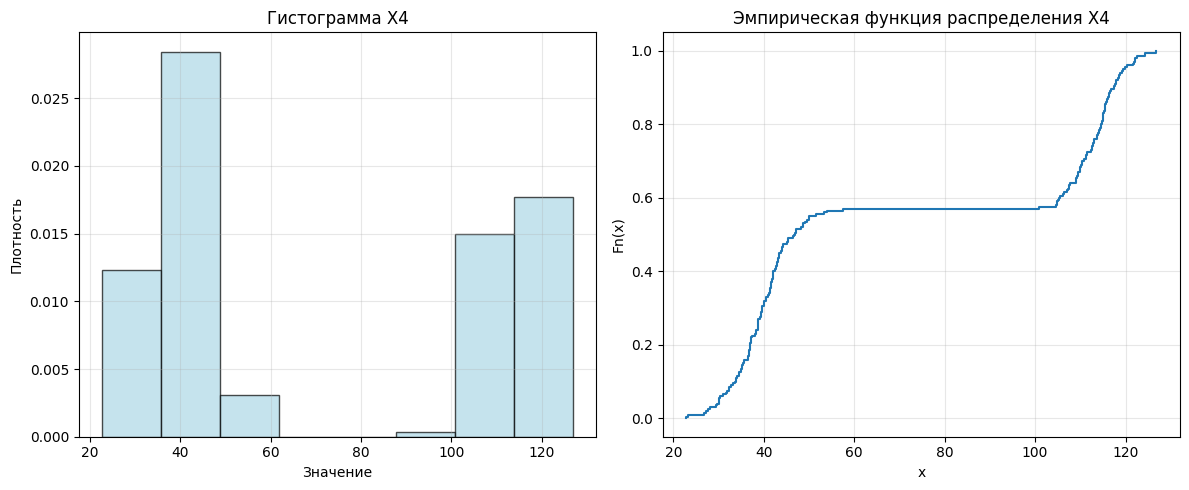

Числовые характеристики X4:
Среднее: 71.30
Медиана: 46.76
Стандартное отклонение: 37.40
Минимум: 22.80
Максимум: 126.84


In [22]:
# Гистограмма с правилом Стерджеса
bins = int(1 + np.log2(n))
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(X4, bins=bins, density=True, alpha=0.7, edgecolor='black', color='lightblue')
plt.title('Гистограмма X4')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.grid(True, alpha=0.3)

# Эмпирическая функция распределения
ecdf = ECDF(X4)

plt.subplot(1, 2, 2)
plt.step(ecdf.x, ecdf.y, where='post')
plt.title('Эмпирическая функция распределения X4')
plt.xlabel('x')
plt.ylabel('Fn(x)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Числовые характеристики
print("Числовые характеристики X4:")
print(f"Среднее: {np.mean(X4):.2f}")
print(f"Медиана: {np.median(X4):.2f}")
print(f"Стандартное отклонение: {np.std(X4, ddof=1):.2f}")
print(f"Минимум: {np.min(X4):.2f}")
print(f"Максимум: {np.max(X4):.2f}")

Гистограмма X4 показывает четкую бимодальность - два явно выраженных пика:

Первый пик: значения примерно 34.36-45.92 (плотность 0.032)
Второй пик: значения примерно 103.72-115.28 (плотность 0.022)

Между ними наблюдается провал: на интервале примерно 57-92 плотность равна 0, что очень похоже на смесь двух разных групп наблюдений.

**Признаки неоднородности данных**

1. Бимодальность гистограммы. Наличие двух разделенных пиков является главным признаком того, что выборка не является однородной и представляет собой смесь двух распределений.

2. Разрыв между группами. Отсутствие наблюдений в промежутке между двумя группами говорит о том, что данные естественным образом распадаются на два кластера без переходной зоны.

3. Расхождение среднего и медианы. Среднее (71.30) существенно отличается от медианы (46.76). Здесь это расхождение объясняется тем, что в выборке смешаны два режима.

4. Большое стандартное отклонение. Стандартное отклонение (37.40) велико по сравнению с разбросом внутри каждой из двух визуально выделяемых групп.

5. Форма эмпирической функции распределения. ЭФР имеет два участка быстрого роста: первый - в области низких значений, второй - в области высоких значений. Между ними наблюдается пологий участок, что характерно для смеси распределений.

In [23]:
# Кластеризация

# Подготовка данных
X4_reshaped = X4.values.reshape(-1, 1)

# K-means кластеризация
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
raw_labels = kmeans.fit_predict(X4_reshaped)

# Упорядочим метки так, чтобы Кластер 1 был с меньшими значениями
centers = kmeans.cluster_centers_.flatten()
order = np.argsort(centers)
labels = np.where(raw_labels == order[0], 0, 1)

# Разделение на кластеры
cluster1 = X4[labels == 0]
cluster2 = X4[labels == 1]

print("Кластеризация X4 (k-means, k=2)")

print(f"\nКластер 1:")
print(f"Размер: {len(cluster1)} ({len(cluster1) / len(X4) * 100:.1f}%)")
print(f"Среднее: {np.mean(cluster1):.2f}")
print(f"Медиана: {np.median(cluster1):.2f}")
print(f"Дисперсия: {np.var(cluster1, ddof=1):.2f}")
print(f"Минимум: {np.min(cluster1):.2f}")
print(f"Максимум: {np.max(cluster1):.2f}")

print(f"\nКластер 2:")
print(f"Размер: {len(cluster2)} ({len(cluster2) / len(X4) * 100:.1f}%)")
print(f"Среднее: {np.mean(cluster2):.2f}")
print(f"Медиана: {np.median(cluster2):.2f}")
print(f"Дисперсия: {np.var(cluster2, ddof=1):.2f}")
print(f"Минимум: {np.min(cluster2):.2f}")
print(f"Максимум: {np.max(cluster2):.2f}")

print(f"\nОбщая выборка X4:")
print(f"Среднее: {np.mean(X4):.2f}")
print(f"Дисперсия: {np.var(X4, ddof=1):.2f}")

Кластеризация X4 (k-means, k=2)

Кластер 1:
Размер: 114 (57.0%)
Среднее: 39.30
Медиана: 39.41
Дисперсия: 41.02
Минимум: 22.80
Максимум: 57.44

Кластер 2:
Размер: 86 (43.0%)
Среднее: 113.71
Медиана: 114.21
Дисперсия: 27.08
Минимум: 100.77
Максимум: 126.84

Общая выборка X4:
Среднее: 71.30
Дисперсия: 1398.94


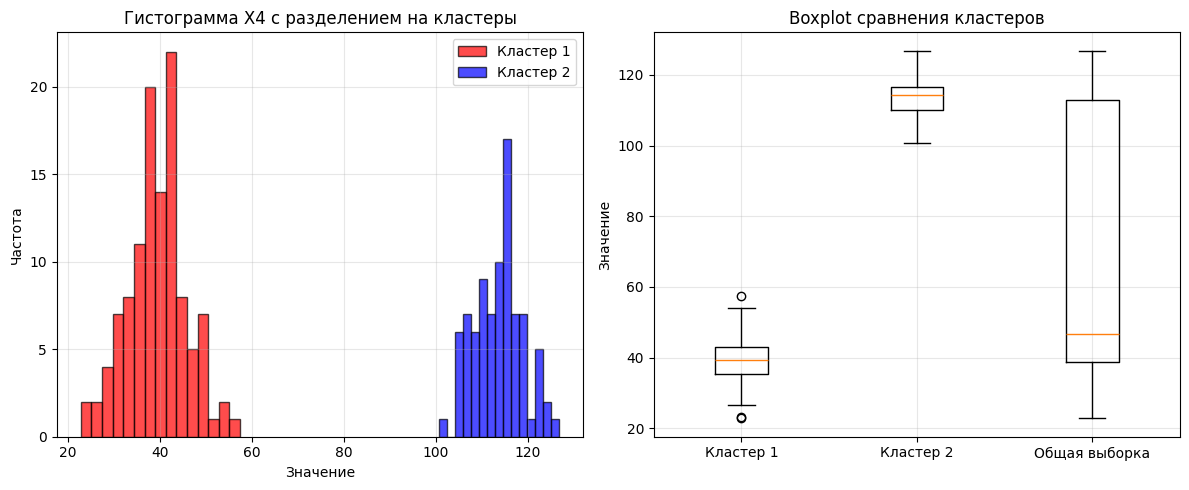

In [24]:
# Визуализация кластеров

# Гистограмма с разделением по кластерам
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(cluster1, bins=15, alpha=0.7, label='Кластер 1', color='red', edgecolor='black')
plt.hist(cluster2, bins=15, alpha=0.7, label='Кластер 2', color='blue', edgecolor='black')
plt.title('Гистограмма X4 с разделением на кластеры')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, alpha=0.3)

# Boxplot для сравнения
plt.subplot(1, 2, 2)
data_to_plot = [cluster1, cluster2, X4]
plt.boxplot(data_to_plot, tick_labels=['Кластер 1', 'Кластер 2', 'Общая выборка'])
plt.title('Boxplot сравнения кластеров')
plt.ylabel('Значение')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Для boxplot

* Нижняя граница ящика (Q1) - 25-й процентиль - 25% данных меньше этого значения
* Линия внутри ящика (Q2) - медиана (50-й процентиль) - центр распределения
* Верхняя граница ящика (Q3) - 75-й процентиль - 75% данных меньше этого значения
* Нижний ус - $Q1 - 1.5 \cdot (Q3 - Q1)$ - нижняя граница для невыбросов
* Верхний ус - $Q3 + 1.5 \cdot (Q3 - Q1)$ - верхняя граница для невыбросов

**Анализ кластеров**

Кластер 1
* Значения сосредоточены в диапазоне 22.80 - 57.44
* Среднее (39.30) и медиана (39.41) практически совпадают, что указывает на симметричное распределение внутри кластера
* Малая дисперсия (41.02) свидетельствует о высокой компактности данных
* Нет выбросов, так как значения сосредоточены в узком интервале

Кластер 2
* Значения сосредоточены в диапазоне 100.77 - 126.84
* Среднее (113.71) и медиана (114.21) близки, распределение внутри кластера также симметрично
* Малая дисперсия (27.08) указывает на компактность данных
* Нет выбросов

Общая выборка:
* Объединяет два компактных кластера, расположенных далеко друг от друга
* Дисперсия (1398.94) огромна по сравнению с дисперсиями внутри кластеров
* Среднее (71.30) находится между средними кластеров и не соответствует центру ни одного из них
* Медиана (46.76) смещена в сторону первого кластера, так как он больше по объему

#### Почему общее среднее плохо описывает смесь двух режимов

1. Общее среднее не существует в реальной структуре выборки. Среднее по X4 равно 71.30, но в окрестности этого значения почти нет наблюдений: между двумя группами есть широкий разрыв.

2. Потеря информации о структуре. Общее среднее сглаживает наличие двух различных групп. Глядя только на среднее, невозможно понять, что данные представляют собой две разные совокупности.

3. Ошибочные выводы. Если бы мы использовали только общее среднее, можно было бы сказать, что "типичное" значение X4 находится около 71.30, хотя реально типичных значений два: около 39.30 и около 113.71.

4. Маскировка различий. Общее среднее скрывает тот факт, что две группы имеют совершенно разные характеристики и расположены далеко друг от друга.

5. Разница между средними кластеров составляет примерно 74.41 единиц, что намного больше внутрикластерного разброса.